# Machine Learning Assignment
## Simple Linear Regression — House Price Prediction

### Objective
This is a simple introductory Machine Learning assignment with two parts.

- **Part A:** Explain basic Machine Learning concepts in your own words.
- **Part B:** Build a Simple Linear Regression model that predicts the price of a house using its size in square feet.

### Dataset
You have been given `simple_housing_data.csv`, containing 200 housing records and only two columns:

- `House_Size_SqFt` — the size of the house in square feet.
- `House_Price` — the price of the house.

Keep your solution simple and make sure you understand every line of code you write.


# PART A — Machine Learning Concepts

### 1. Regression
Regression is a type of machine learning where the model predicts a **continuous number**. The answer can be any value in a range, not a category. Example: predicting the price of a house from its size, or tomorrow's temperature.

### 2. Classification
Classification is where the model predicts which **category (class)** something belongs to. The output is a label, not a number.

### 3. Supervised Learning
In supervised learning the model learns from data that already has the **correct answers (labels)**. It studies the inputs together with the known outputs, learns the pattern, and then predicts the output for new data. Regression and classification are both supervised learning.

### 4. Unsupervised Learning
In unsupervised learning the data has **no labels**. The model looks for hidden structure or patterns on its own, such as grouping similar items together. Example: grouping customers into segments based on their buying habits, without telling the model what the groups are.

### 5. Reinforcement Learning
In reinforcement learning an **agent** learns by interacting with an environment. It takes actions, receives **rewards or penalties**, and gradually learns the strategy that earns the most reward. Example: a program learning to play chess or a robot learning to walk by trial and error.

# PART B — Simple Linear Regression

## Scenario
You have been given information about the **size of houses** and their corresponding **prices**.

Your task is to train a Simple Linear Regression model that learns the relationship between house size and house price.

- **Feature (X):** `House_Size_SqFt`
- **Target (y):** `House_Price`


## Step 1 — Import the Required Libraries

Import the libraries you need to:
- work with the dataset;
- split the data into training and testing sets;
- create a Linear Regression model.


In [1]:
import pandas as pd

## Step 2 — Load the Dataset

Use Pandas to load `simple_housing_data.csv`.

Display the first few rows of the dataset to confirm that it loaded correctly.


In [25]:
df = pd.read_csv("data/Simple Housing Data.csv")
df.head()

,House_Size_SqFt,House_Price
0,500,125800
1,510,120700
2,537,153400
3,583,123500
4,596,122300


In [12]:
X = df[["House_Size_SqFt"]]
y = df["House_Price"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (200, 1)
y shape: (200,)


## Step 4 — Split the Dataset

Split your data into:
- training data;
- testing data.

The training data will be used to train the model.


In [26]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=11
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 160
Testing rows: 40


## Step 5 — Create and Train the Model

Create a **Linear Regression** model.

Train the model using your training data.


In [16]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

print("Slope (price per extra sq ft):", model.coef_[0])
print("Intercept:", model.intercept_)

Slope (price per extra sq ft): 150.13129678465688
Intercept: 45333.82916729158


## Step 6 — Make Predictions

Use your trained model to make predictions using the test data.


   Actual      Predicted
0  380200  365113.491319
1  158800  155830.463601
2  179400  194113.944281
3  493100  481915.640217
4  441600  426367.060407
MAE: 12708.864030677334
R2 score: 0.9819421750492037


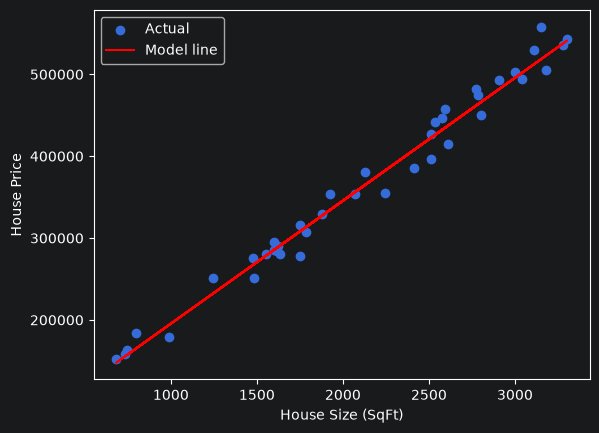

In [20]:
y_pred = model.predict(X_test)

# Compare a few actual vs predicted prices
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt
comparison = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred})
print(comparison.head())

print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2 score:", r2_score(y_test, y_pred))

# Optional: visualize the fitted line
plt.scatter(X_test, y_test, label="Actual")
plt.plot(X_test, y_pred, color="red", label="Model line")
plt.xlabel("House Size (SqFt)")
plt.ylabel("House Price")
plt.legend()
plt.show()

## Step 7 — Predict the Price of a New House

Use the trained model to predict the price of a house that is **2,000 square feet**.

Then choose at least **two other house sizes** and predict their prices as well.

Use your model's `.predict()` method.


In [18]:
# Use a DataFrame with the same column name used in training
new_sizes = pd.DataFrame({"House_Size_SqFt": [2000, 1200, 3000]})
new_prices = model.predict(new_sizes)

for size, price in zip(new_sizes["House_Size_SqFt"], new_prices):
    print(f"A house of {size} sq ft is predicted to cost about {price:,.2f}")

A house of 2000 sq ft is predicted to cost about 345,596.42
A house of 1200 sq ft is predicted to cost about 225,491.39
A house of 3000 sq ft is predicted to cost about 495,727.72


# Optional Step

## Step 8 — Short Explanation

Briefly answer the following:

1. What was the input or feature used to train the model?
2. What was the target the model was trying to predict?
3. What does it mean to train the Linear Regression model?
4. What happens when you give the trained model a new house size such as 2,000 square feet?

### Submission
Submit your completed Jupyter Notebook.

Make sure your notebook runs correctly from beginning to end and that you understand the code you wrote.

**Good luck!**


### Step 8 — Answers

1. **Input (feature):** the house size in square feet (`House_Size_SqFt`).
2. **Target:** the house price (`House_Price`).
3. **Training a Linear Regression model** means the model looks at the training examples and finds the straight line (price = slope × size + intercept) that fits the data best, i.e. the slope and intercept that make the prediction errors as small as possible.
4. **Predicting for 2,000 sq ft:** the model plugs 2,000 into its learned line (slope × 2000 + intercept) and returns the estimated price for a house of that size.